# ARTI 403 — Image Processing
## Lab 1 — Basics of Programming with Python

**College of Computer Science and Information Technology — Department of Computer Engineering**  
**Imam Abdulrahman Bin Faisal University — 2026 / 2027**

| | |
|---|---|
| **Session topic** | Basics of Programming with Python |
| **Session No.** | 1 |
| **Duration** | 100 minutes |
| **Student name** | Abdulrahman Saleh Alaamri |
| **Student ID** | 2240002427 |

**Outcome #1:** Explain how digital images are represented and manipulated in a computer.

## 1. Environment setup

I installed Anaconda. It comes with Jupyter and Spyder. Then I installed the libraries I need for the course:

```bash
pip install numpy scipy opencv-python scikit-image pillow matplotlib
```

The next cell checks that everything is installed.

In [1]:
import sys
import numpy as np
import cv2
import PIL
import scipy
import skimage
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image

%matplotlib inline

print("Python     :", sys.version.split()[0])
print("NumPy      :", np.__version__)
print("SciPy      :", scipy.__version__)
print("OpenCV     :", cv2.__version__)
print("scikit-image:", skimage.__version__)
print("Pillow     :", PIL.__version__)
print("Matplotlib :", matplotlib.__version__)

Python     : 3.14.5
NumPy      : 2.5.3
SciPy      : 1.18.1
OpenCV     : 5.0.0
scikit-image: 0.26.0
Pillow     : 12.3.0
Matplotlib : 3.11.2


## 2. Task 1: Python and NumPy practice

I practiced the Python basics cheat sheet and the NumPy cheat sheet. An image is just a NumPy array, so this is the base for all the next labs.

### Python basics

In [2]:
width = 256
height = 256
scale = 0.5
image_name = "lena"
is_gray = True

print(width, type(width))
print(scale, type(scale))
print(image_name, type(image_name))
print(is_gray, type(is_gray))

print("number of pixels :", width * height)
print("half the width   :", int(width * scale))
print("width // 3       :", width // 3)
print("width % 3        :", width % 3)
print("2 ** 8           :", 2 ** 8)

256 <class 'int'>
0.5 <class 'float'>
lena <class 'str'>
True <class 'bool'>
number of pixels : 65536
half the width   : 128
width // 3       : 85
width % 3        : 1
2 ** 8           : 256


In [3]:
title = "Digital Image Processing"

print(title.upper())
print(title.lower())
print(title.replace("Digital", "ARTI 403"))
print(len(title))
print(title[0:7])
print(title.split())
print(f"the image {image_name} is {width}x{height} pixels")

DIGITAL IMAGE PROCESSING
digital image processing
ARTI 403 Image Processing
24
Digital
['Digital', 'Image', 'Processing']
the image lena is 256x256 pixels


In [4]:
gray_levels = [0, 32, 64, 128, 192, 255]

print(gray_levels)
print(gray_levels[0], gray_levels[-1])
print(gray_levels[1:4])

gray_levels.append(200)
gray_levels.insert(1, 16)
gray_levels.remove(200)
gray_levels.sort()
print(gray_levels)
print(min(gray_levels), max(gray_levels), sum(gray_levels))

size = (width, height)
print(size)

[0, 32, 64, 128, 192, 255]
0 255
[32, 64, 128]
[0, 16, 32, 64, 128, 192, 255]
0 255 687
(256, 256)


In [5]:
image_info = {"name": "lena_gray_256", "format": "tif", "size": size}

print(image_info)
print(list(image_info.keys()))
print(image_info["size"])
for key, value in image_info.items():
    print(key, "=", value)

A = {1, 2, 3, 4}
B = {3, 4, 5, 6}
print("union        :", A | B)
print("intersection :", A & B)
print("difference   :", A - B)
print("symmetric    :", A ^ B)

{'name': 'lena_gray_256', 'format': 'tif', 'size': (256, 256)}
['name', 'format', 'size']
(256, 256)
name = lena_gray_256
format = tif
size = (256, 256)
union        : {1, 2, 3, 4, 5, 6}
intersection : {3, 4}
difference   : {1, 2}
symmetric    : {1, 2, 5, 6}


In [6]:
pixel = 130

if pixel > 200:
    category = "bright"
elif pixel > 100:
    category = "mid-gray"
else:
    category = "dark"
print(pixel, "is", category)

for g in [0, 128, 255]:
    print("gray level", g)

for i in range(0, 5):
    print("row", i)

n = 256
while n > 16:
    print("resolution", n, "x", n)
    n //= 2

squares = [i ** 2 for i in range(6)]
negatives = [255 - g for g in [0, 64, 128, 255]]
print(squares)
print(negatives)

130 is mid-gray
gray level 0
gray level 128
gray level 255
row 0
row 1
row 2
row 3
row 4
resolution 256 x 256
resolution 128 x 128
resolution 64 x 64
resolution 32 x 32
[0, 1, 4, 9, 16, 25]
[255, 191, 127, 0]


In [7]:
def bits_to_levels(bits):
    return 2 ** bits


def image_memory(width, height, bits=8, channels=1):
    return width * height * channels * bits // 8


for b in (1, 2, 4, 8):
    print(b, "bit ->", bits_to_levels(b), "gray levels")

print("256x256 gray image :", image_memory(256, 256), "bytes")
print("256x256 RGB image  :", image_memory(256, 256, 8, 3), "bytes")

1 bit -> 2 gray levels
2 bit -> 4 gray levels
4 bit -> 16 gray levels
8 bit -> 256 gray levels
256x256 gray image : 65536 bytes
256x256 RGB image  : 196608 bytes


### NumPy basics

In [8]:
a = np.array([1, 2, 3, 4, 5])
b = np.zeros((3, 4), dtype=np.uint8)
c = np.ones((3, 4), dtype=np.uint8) * 255
d = np.full((2, 3), 128, dtype=np.uint8)
e = np.arange(0, 256, 64)
f = np.linspace(0, 255, 5)
g = np.eye(4, dtype=np.uint8)

print("a =", a)
print("e =", e)
print("f =", f)
print("b (black) =\n", b)
print("c (white) =\n", c)
print("d (gray) =\n", d)
print("g (identity) =\n", g)

a = [1 2 3 4 5]
e = [  0  64 128 192]
f = [  0.    63.75 127.5  191.25 255.  ]
b (black) =
 [[0 0 0 0]
 [0 0 0 0]
 [0 0 0 0]]
c (white) =
 [[255 255 255 255]
 [255 255 255 255]
 [255 255 255 255]]
d (gray) =
 [[128 128 128]
 [128 128 128]]
g (identity) =
 [[1 0 0 0]
 [0 1 0 0]
 [0 0 1 0]
 [0 0 0 1]]


In [9]:
patch = np.array([[10, 20, 30, 40],
                  [50, 60, 70, 80],
                  [90, 100, 110, 120]], dtype=np.uint8)

print(patch)
print("shape    :", patch.shape)
print("size     :", patch.size)
print("ndim     :", patch.ndim)
print("dtype    :", patch.dtype)
print("itemsize :", patch.itemsize)
print("nbytes   :", patch.nbytes)

[[ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]]
shape    : (3, 4)
size     : 12
ndim     : 2
dtype    : uint8
itemsize : 1
nbytes   : 12


In [10]:
print("patch[0, 0]    :", patch[0, 0])
print("patch[2, 3]    :", patch[2, 3])
print("patch[-1, -1]  :", patch[-1, -1])
print("patch[0]       :", patch[0])
print("patch[:, 1]    :", patch[:, 1])
print("patch[0:2, 1:3] =\n", patch[0:2, 1:3])
print("patch[::-1] =\n", patch[::-1])
print("patch[:, ::-1] =\n", patch[:, ::-1])

patch[0, 0]    : 10
patch[2, 3]    : 120
patch[-1, -1]  : 120
patch[0]       : [10 20 30 40]
patch[:, 1]    : [ 20  60 100]
patch[0:2, 1:3] =
 [[20 30]
 [60 70]]
patch[::-1] =
 [[ 90 100 110 120]
 [ 50  60  70  80]
 [ 10  20  30  40]]
patch[:, ::-1] =
 [[ 40  30  20  10]
 [ 80  70  60  50]
 [120 110 100  90]]


In [11]:
print("patch + 10 =\n", patch + 10)
print("patch // 2 =\n", patch // 2)
print("255 - patch =\n", 255 - patch)
print("patch * 2 =\n", patch * 2)

mask = patch > 60
print("mask =\n", mask)
print("pixels above 60 :", mask.sum())
print("thresholded =\n", np.where(patch > 60, 255, 0).astype(np.uint8))

patch + 10 =
 [[ 20  30  40  50]
 [ 60  70  80  90]
 [100 110 120 130]]
patch // 2 =
 [[ 5 10 15 20]
 [25 30 35 40]
 [45 50 55 60]]
255 - patch =
 [[245 235 225 215]
 [205 195 185 175]
 [165 155 145 135]]
patch * 2 =
 [[ 20  40  60  80]
 [100 120 140 160]
 [180 200 220 240]]
mask =
 [[False False False False]
 [False False  True  True]
 [ True  True  True  True]]
pixels above 60 : 6
thresholded =
 [[  0   0   0   0]
 [  0   0 255 255]
 [255 255 255 255]]


In [12]:
print("min    :", patch.min())
print("max    :", patch.max())
print("mean   :", patch.mean())
print("std    :", patch.std())
print("sum    :", patch.sum())
print("median :", np.median(patch))
print("mean of columns :", patch.mean(axis=0))
print("mean of rows    :", patch.mean(axis=1))

print("flatten :", patch.flatten())
print("reshape(4, 3) =\n", patch.reshape(4, 3))
print("transpose =\n", patch.T)
print("vstack =\n", np.vstack([patch, patch]))
print("hstack =\n", np.hstack([patch, patch]))

min    : 10
max    : 120
mean   : 65.0
std    : 34.52052529534663
sum    : 780
median : 65.0
mean of columns : [50. 60. 70. 80.]
mean of rows    : [ 25.  65. 105.]
flatten : [ 10  20  30  40  50  60  70  80  90 100 110 120]
reshape(4, 3) =
 [[ 10  20  30]
 [ 40  50  60]
 [ 70  80  90]
 [100 110 120]]
transpose =
 [[ 10  50  90]
 [ 20  60 100]
 [ 30  70 110]
 [ 40  80 120]]
vstack =
 [[ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]
 [ 10  20  30  40]
 [ 50  60  70  80]
 [ 90 100 110 120]]
hstack =
 [[ 10  20  30  40  10  20  30  40]
 [ 50  60  70  80  50  60  70  80]
 [ 90 100 110 120  90 100 110 120]]


A `uint8` pixel can only hold 0 to 255. If the result is bigger, it wraps around. This is a common mistake in image processing.

In [13]:
u = np.array([250, 251, 252], dtype=np.uint8)

print("uint8 + 10    :", u + 10)
print("with np.clip  :", np.clip(u.astype(np.int16) + 10, 0, 255).astype(np.uint8))
print("with cv2.add  :", cv2.add(u.reshape(1, 3), np.uint8([[10, 10, 10]])).ravel())

uint8 + 10    : [4 5 6]
with np.clip  : [255 255 255]
with cv2.add  : [255 255 255]


**Note:** `250 + 10` should be 260 but the `uint8` result is 4. With `np.clip` or `cv2.add` the value stays at 255.

## 3. Task 2: Loading and visualizing images

### (a) Using OpenCV

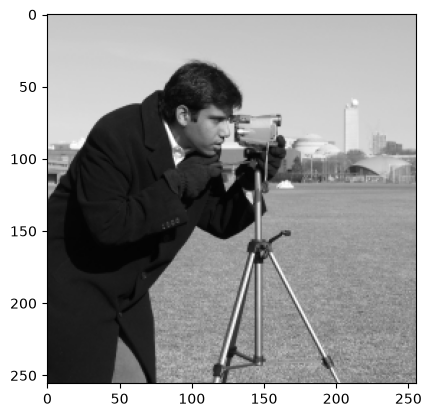

In [14]:
img = cv2.imread('../images/cameraman.tif')

plt.imshow(img)
plt.show()

The image looks fine, but `cv2.imread` gives a 3-channel **BGR** image even for a gray file, and matplotlib expects **RGB**. I cannot see a color problem because this image is gray. For a gray image it is better to read it as one channel and use `cmap='gray'`.

default read : (256, 256, 3)
gray read    : (256, 256)


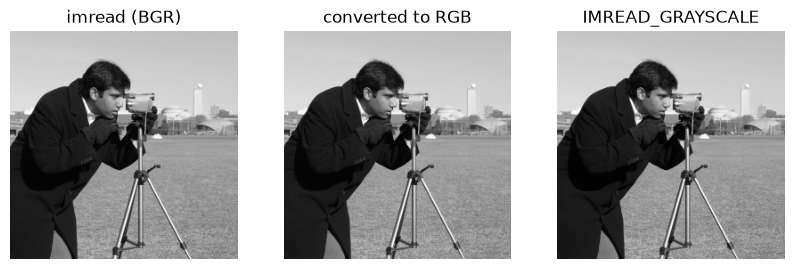

In [15]:
img_gray = cv2.imread('../images/cameraman.tif', cv2.IMREAD_GRAYSCALE)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

print("default read :", img.shape)
print("gray read    :", img_gray.shape)

plt.figure(figsize=(10, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title('imread (BGR)')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(img_rgb)
plt.title('converted to RGB')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_gray, cmap='gray')
plt.title('IMREAD_GRAYSCALE')
plt.axis('off')

plt.show()

### (b) Using PIL

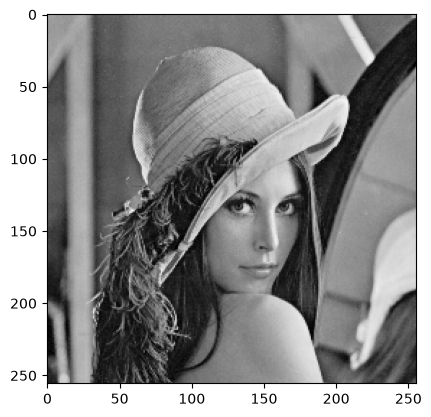

In [16]:
img2 = Image.open('../images/lena_gray_256.tif')

plt.imshow(img2, cmap='gray')
plt.show()

In [17]:
print("type   :", type(img2))
print("format :", img2.format)
print("mode   :", img2.mode)
print("size   :", img2.size)
print("array  :", np.array(img2).shape)

type   : <class 'PIL.TiffImagePlugin.TiffImageFile'>
format : TIFF
mode   : L
size   : (256, 256)
array  : (256, 256)


PIL gives the size as (width, height). NumPy and OpenCV give (rows, columns), which is (height, width).

## 4. Task 3: Image storing

### (a) Using OpenCV

In [18]:
import os

os.makedirs('output', exist_ok=True)

cv2.imwrite('output/new_image.jpg', img)
print("saved:", os.path.exists('output/new_image.jpg'))

saved: True


### (b) Using PIL

In [19]:
img2.save('output/new_image2.jpg')
print("saved:", os.path.exists('output/new_image2.jpg'))

cv2.imwrite('output/cameraman_copy.png', img_gray)
img2.save('output/lena_copy.bmp')

for name in sorted(os.listdir('output')):
    print(name, os.path.getsize('output/' + name), "bytes")

saved: True


cameraman_copy.png 37379 bytes
lena_copy.bmp 66614 bytes
new_image.jpg 23485 bytes
new_image2.jpg 11433 bytes


In [20]:
lena_original = np.array(img2, dtype=np.int16)
lena_jpeg = np.array(Image.open('output/new_image2.jpg'), dtype=np.int16)

print("BMP size  :", os.path.getsize('output/lena_copy.bmp'), "bytes")
print("JPEG size :", os.path.getsize('output/new_image2.jpg'), "bytes")
print("max difference after JPEG  :", np.abs(lena_original - lena_jpeg).max())
print("mean difference after JPEG :", round(np.abs(lena_original - lena_jpeg).mean(), 3))

BMP size  : 66614 bytes
JPEG size : 11433 bytes
max difference after JPEG  : 37
mean difference after JPEG : 3.345


The JPEG file is much smaller, but it is lossy: the pixel values changed after saving. PNG and BMP keep the pixels exactly.

## 5. Task 4: Display the image as an array

In [21]:
print(img.shape)
print(img)

(256, 256, 3)
[[[200 200 200]
  [200 200 200]
  [200 200 200]
  ...
  [190 190 190]
  [190 190 190]
  [190 190 190]]

 [[200 200 200]
  [199 199 199]
  [200 200 200]
  ...
  [190 190 190]
  [190 190 190]
  [190 190 190]]

 [[200 200 200]
  [200 200 200]
  [199 199 199]
  ...
  [191 191 191]
  [191 191 191]
  [191 191 191]]

 ...

 [[ 25  25  25]
  [ 25  25  25]
  [ 24  24  24]
  ...
  [138 138 138]
  [146 146 146]
  [115 115 115]]

 [[ 25  25  25]
  [ 25  25  25]
  [ 26  26  26]
  ...
  [141 141 141]
  [160 160 160]
  [146 146 146]]

 [[ 25  25  25]
  [ 26  26  26]
  [ 25  25  25]
  ...
  [143 143 143]
  [148 148 148]
  [153 153 153]]]


In [22]:
img_array = np.array(img2)

print(img_array.shape)
print(img_array)

(256, 256)
[[162 162 162 ... 168 171 155]
 [162 162 162 ... 168 171 155]
 [162 162 162 ... 168 171 155]
 ...
 [ 48  57  54 ...  75  97  88]
 [ 46  50  52 ...  89 100  98]
 [ 44  55  54 ...  97 100 105]]


[[ 77  82  74  71  64  85  83  77  63  57]
 [ 77  84  64  77  87  87  66  66  43  41]
 [ 76  60  66  99  73  65  47  45  42  65]
 [ 63  70  98  94  62  44  39  41  44  67]
 [ 83  90  96  81  54  49  50  42  47  82]
 [ 77 105 101  66  55  52  54  42  55  81]
 [ 66  91  90  74  56  47  45  45  67  66]
 [ 61 100  83  68  77  65  62  51  71  59]
 [ 53  73  81  85  72  96  61  37  75  63]
 [ 51  73  89  62  71  84  59  47  73  66]]


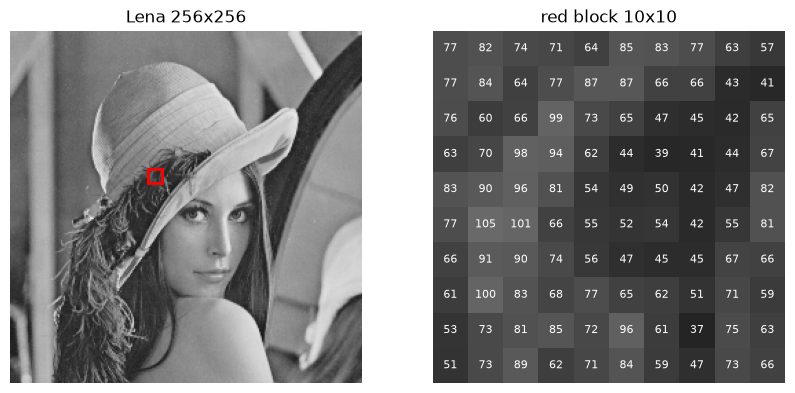

In [23]:
block = img_array[100:110, 100:110]
print(block)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))

ax[0].imshow(img_array, cmap='gray', vmin=0, vmax=255)
ax[0].add_patch(plt.Rectangle((100, 100), 10, 10, edgecolor='red', facecolor='none', lw=2))
ax[0].set_title('Lena 256x256')
ax[0].axis('off')

ax[1].imshow(block, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('red block 10x10')
ax[1].axis('off')
for i in range(10):
    for j in range(10):
        ax[1].text(j, i, block[i, j], ha='center', va='center', fontsize=8,
                   color='black' if block[i, j] > 127 else 'white')

plt.show()

Each pixel is just a number from 0 (black) to 255 (white).

## 6. Assessment: operations on the array using NumPy

All the operations below are done with NumPy on the Lena array.

In [24]:
A = np.array(Image.open('../images/lena_gray_256.tif'))

print("shape :", A.shape, A.dtype)
print("min   :", A.min())
print("max   :", A.max())
print("mean  :", round(A.mean(), 2))
print("std   :", round(A.std(), 2))
print("median:", np.median(A))
print("distinct gray levels:", len(np.unique(A)))

shape : (256, 256) uint8
min   : 26
max   : 242
mean  : 124.01
std   : 47.84
median: 129.0
distinct gray levels: 210


crop : (130, 130)
row  : (256,)


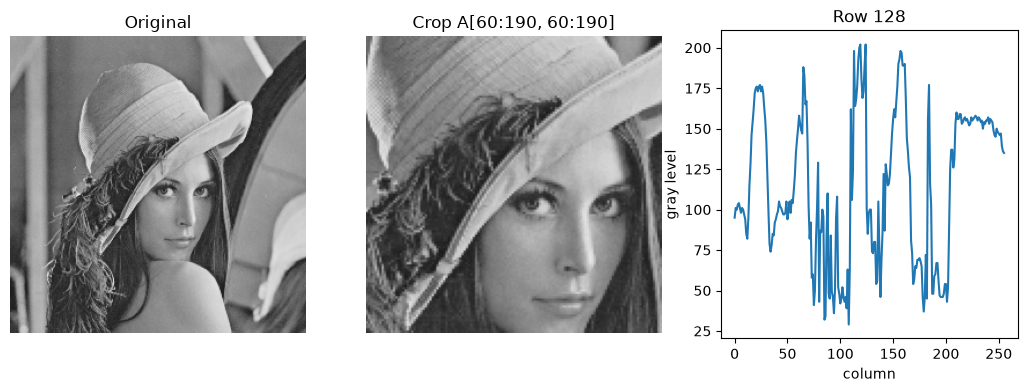

In [25]:
crop = A[60:190, 60:190]
row = A[128, :]

print("crop :", crop.shape)
print("row  :", row.shape)

fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(A, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(crop, cmap='gray', vmin=0, vmax=255)
ax[1].set_title('Crop A[60:190, 60:190]')
ax[1].axis('off')

ax[2].plot(row)
ax[2].set_title('Row 128')
ax[2].set_xlabel('column')
ax[2].set_ylabel('gray level')

plt.show()

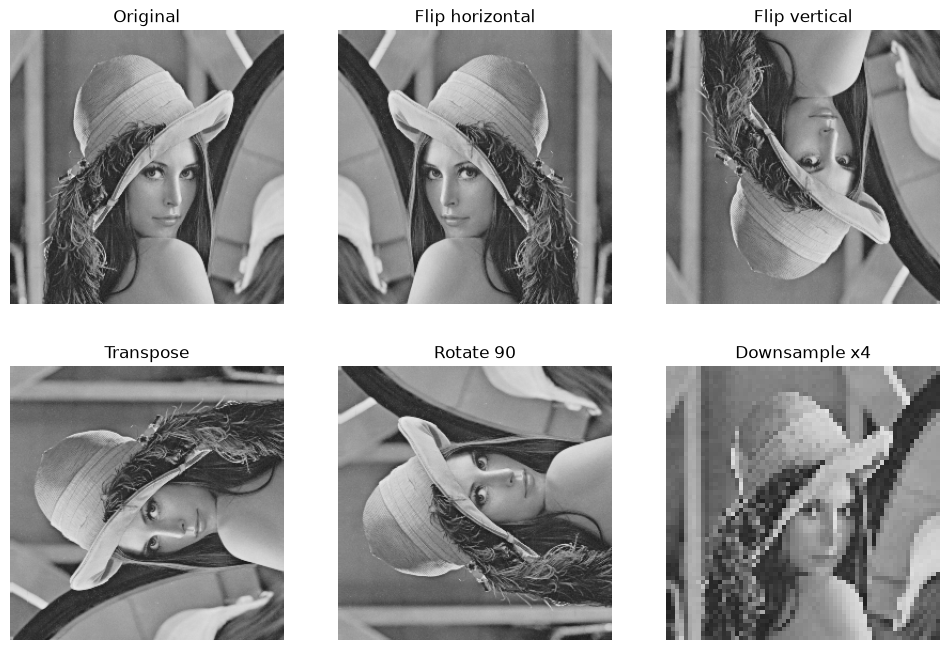

In [26]:
flip_h = A[:, ::-1]
flip_v = A[::-1, :]
transpose = A.T
rot90 = np.rot90(A)
downsample = A[::4, ::4]

titles = ['Original', 'Flip horizontal', 'Flip vertical', 'Transpose', 'Rotate 90', 'Downsample x4']
imgs = [A, flip_h, flip_v, transpose, rot90, downsample]

plt.figure(figsize=(12, 8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

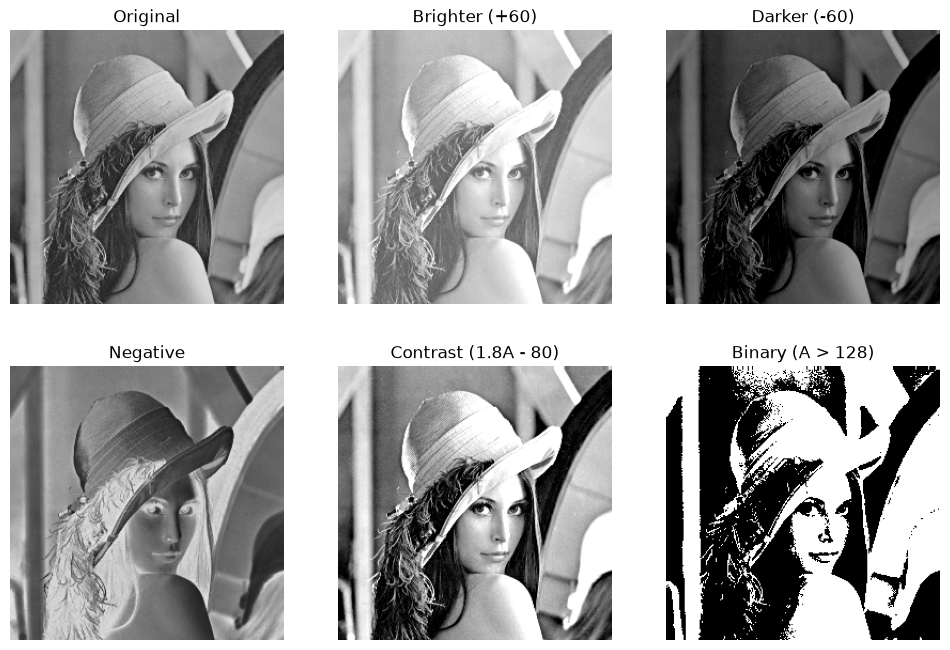

In [27]:
A16 = A.astype(np.int16)
brighter = np.clip(A16 + 60, 0, 255).astype(np.uint8)
darker = np.clip(A16 - 60, 0, 255).astype(np.uint8)
negative = 255 - A
contrast = np.clip(1.8 * A16 - 80, 0, 255).astype(np.uint8)
binary = np.where(A > 128, 255, 0).astype(np.uint8)

titles = ['Original', 'Brighter (+60)', 'Darker (-60)', 'Negative', 'Contrast (1.8A - 80)', 'Binary (A > 128)']
imgs = [A, brighter, darker, negative, contrast, binary]

plt.figure(figsize=(12, 8))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(2, 3, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

pixels above 150 : 20681 (31.6 %)
their mean value : 177.42


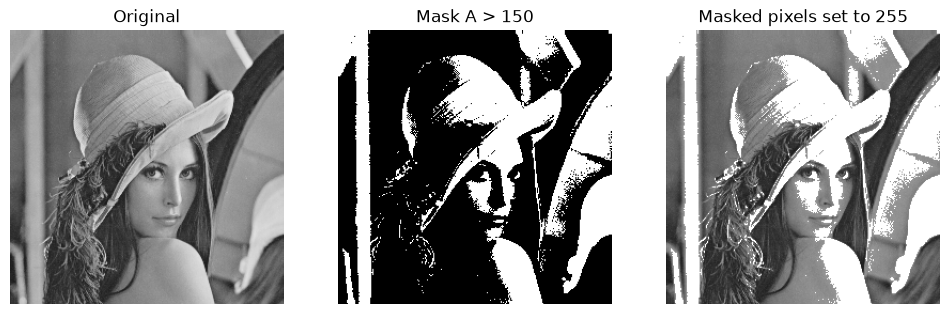

In [28]:
mask = A > 150
print("pixels above 150 :", mask.sum(), f"({100 * mask.mean():.1f} %)")
print("their mean value :", round(A[mask].mean(), 2))

highlighted = A.copy()
highlighted[mask] = 255

fig, ax = plt.subplots(1, 3, figsize=(12, 4))

ax[0].imshow(A, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Original')
ax[0].axis('off')

ax[1].imshow(mask, cmap='gray')
ax[1].set_title('Mask A > 150')
ax[1].axis('off')

ax[2].imshow(highlighted, cmap='gray', vmin=0, vmax=255)
ax[2].set_title('Masked pixels set to 255')
ax[2].axis('off')

plt.show()

flatten : (65536,)
reshape : (128, 512)
hstack  : (256, 512)
vstack  : (512, 256)
dstack  : (256, 256, 3)


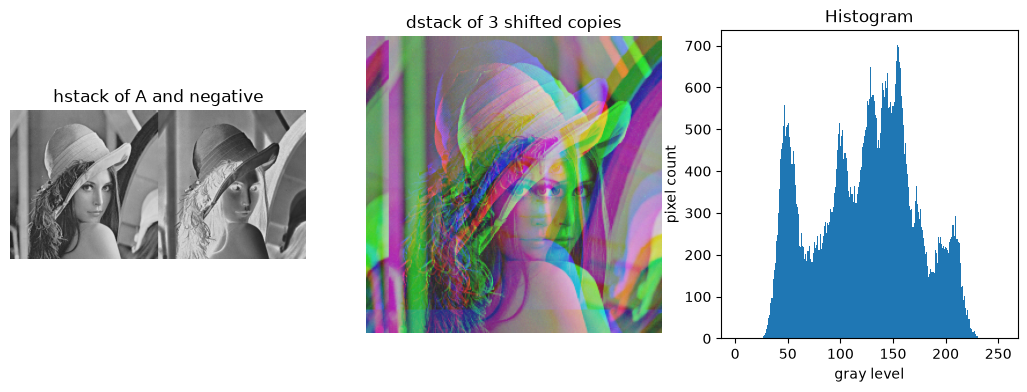

In [29]:
flat = A.flatten()
print("flatten :", flat.shape)
print("reshape :", A.reshape(128, 512).shape)
print("hstack  :", np.hstack([A, negative]).shape)
print("vstack  :", np.vstack([A, negative]).shape)

rgb = np.dstack([A, np.roll(A, 20, axis=1), np.roll(A, -20, axis=0)])
print("dstack  :", rgb.shape)

hist, bins = np.histogram(flat, bins=256, range=(0, 256))

fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(np.hstack([A, negative]), cmap='gray', vmin=0, vmax=255)
ax[0].set_title('hstack of A and negative')
ax[0].axis('off')

ax[1].imshow(rgb)
ax[1].set_title('dstack of 3 shifted copies')
ax[1].axis('off')

ax[2].bar(bins[:-1], hist, width=1.0)
ax[2].set_title('Histogram')
ax[2].set_xlabel('gray level')
ax[2].set_ylabel('pixel count')

plt.show()

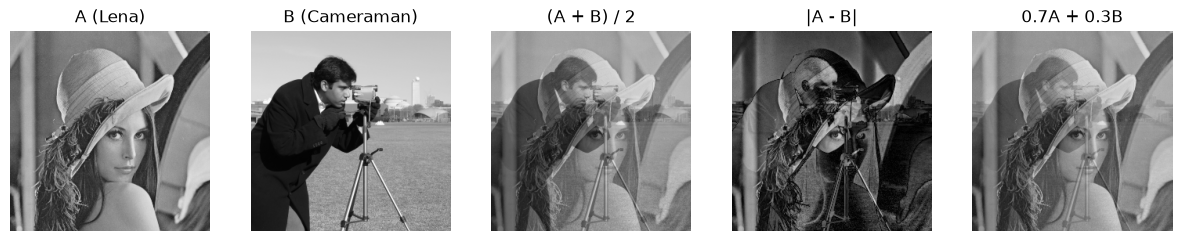

In [30]:
B = np.array(Image.open('../images/cameraman.tif'))

average = ((A.astype(np.int16) + B.astype(np.int16)) // 2).astype(np.uint8)
difference = np.abs(A.astype(np.int16) - B.astype(np.int16)).astype(np.uint8)
blend = np.clip(0.7 * A + 0.3 * B, 0, 255).astype(np.uint8)

titles = ['A (Lena)', 'B (Cameraman)', '(A + B) / 2', '|A - B|', '0.7A + 0.3B']
imgs = [A, B, average, difference, blend]

plt.figure(figsize=(15, 3.5))
for i, (im, t) in enumerate(zip(imgs, titles), 1):
    plt.subplot(1, 5, i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(t)
    plt.axis('off')
plt.show()

## 7. Conclusion

- I installed the tools and checked the versions of all the libraries.
- I practiced Python (variables, strings, lists, dictionaries, sets, loops, functions) and NumPy (arrays, indexing, math, statistics).
- OpenCV reads an image as a NumPy array in **BGR** order. PIL gives an `Image` object with the size as (width, height).
- I saved images with `cv2.imwrite()` and `Image.save()`. JPEG is lossy, but PNG and BMP are lossless.
- An image is a 2-D array (gray) or a 3-D array (color), so processing an image means doing math on numbers with NumPy.
- I must be careful with the `uint8` range because values wrap around after 255.